In [ ]:
import torch
from torch.utils.data import Dataset
from torchvision import datasets
from torchvision.transforms import v2
import matplotlib.pyplot as plt


training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])
)

100.0%
100.0%
100.0%
100.0%


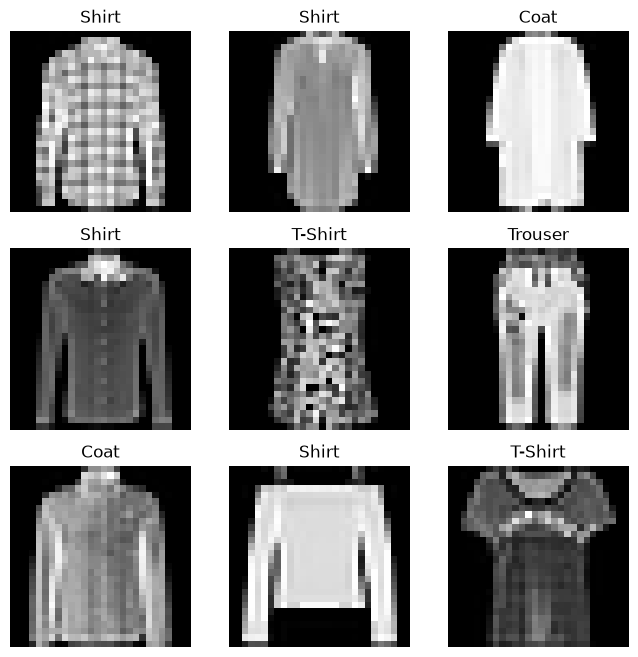

In [2]:
labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}
figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

In [ ]:
import os
import pandas as pd
from torchvision.io import decode_image

class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, transform=None, target_transform=None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform

    def __len__(self):
        return len(self.img_labels)

    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0])
        image = decode_image(img_path)
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

In [4]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(training_data, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=64, shuffle=True)

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


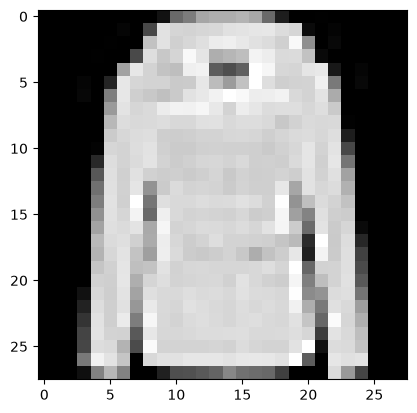

Label: 4


In [5]:
# Display image and label.
train_features, train_labels = next(iter(train_dataloader))
print(f"Feature batch shape: {train_features.size()}")
print(f"Labels batch shape: {train_labels.size()}")
img = train_features[0].squeeze()
label = train_labels[0]
plt.imshow(img, cmap="gray")
plt.show()
print(f"Label: {label}")

In [ ]:
from torch import nn
from models import NeuralNetwork

device = "cpu"
model = NeuralNetwork().to(device)
print(model)

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [15]:
import wandb

wandb.login()

wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results
wandb: WARNING Invalid choice
wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.forge.coreweave.com. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://forge.coreweave.com/wandb/authorize?ref=models
wandb: Store your API key securely and do not share it.
wandb: No netrc file found, creating one.
wandb: Appending key for api.forge.coreweave.com to your netrc file: C:\Users\mults\_netrc
wandb: Currently logged in as: dwight-paniagua (dwight-paniagua-university-of-rhode-island) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


True

In [ ]:
import random

# Start a new wandb run to track this script.
run = wandb.init(
    # Set the wandb entity where your project will be logged (generally your team name).
    entity="dwight-paniagua-university-of-rhode-island",
    # Set the wandb project where this run will be logged.
    project="my-awesome-project",
    # Track hyperparameters and run metadata.
    config={
        "learning_rate": 0.001,
        "architecture": "NN",
        "dataset": "Fashion-MNIST",
        "epochs": 10,
    },
)

# Simulate training.
epochs = 10
offset = random.random() / 5
for epoch in range(2, epochs):
    acc = 1 - 2**-epoch - random.random() / epoch - offset
    loss = 2**-epoch + random.random() / epoch + offset

    # Log metrics to wandb.
    run.log({"acc": acc, "loss": loss})

# Finish the run and upload any remaining data.
run.finish()

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


acc,▁▅▆▇▇██▇
loss,█▂▂▂▂▂▁▁
acc,0.87384
loss,0.06364


In [ ]:
import torch.optim as optim

# Define the training function that W&B will execute
def train():
    # Initialize the wandb run. This automatically receives hyperparameters from the agent.
    with wandb.init() as run:
        config = wandb.config

        # Instantiate model and optimizer using variables from wandb.config
        model = NeuralNetwork().to(device)
        optimizer = optim.Adam(model.parameters(), lr=config.lr)
        criterion = nn.CrossEntropyLoss()

        # Training Loop
        for epoch in range(config.epochs):
            model.train()
            epoch_loss = 0.0
            correct = 0
            total = 0
            
            for batch_X, batch_y in train_dataloader:
                optimizer.zero_grad()
                outputs = model(batch_X)
                loss = criterion(outputs, batch_y)
                loss.backward()
                optimizer.step()
                
                # Track statistics
                epoch_loss += loss.item() * batch_X.size(0)
                _, predicted = torch.max(outputs.data, 1)
                total += batch_y.size(0)
                correct += (predicted == batch_y).sum().item()
            
            # Calculate metrics
            avg_loss = epoch_loss / total
            accuracy = correct / total
            
            # Log metrics to W&B
            wandb.log({
                "epoch": epoch,
                "loss": avg_loss,
                "accuracy": accuracy
            })

# Define your hyperparameter tuning boundaries
sweep_config = {
    'method': 'bayes',  # 'grid', 'random', or 'bayes'
    'metric': {
        'name': 'loss',
        'goal': 'minimize'
    },
    'parameters': {
        'epochs': {'value': 5},
        'lr': {                                    # W&B passes this to config.lr
            'distribution': 'log_uniform_values',
            'min': 1e-4,
            'max': 1e-2
        }
    }
}

# Initialize and launch the sweep
sweep_id = wandb.sweep(sweep=sweep_config, project="my-awesome-project")

# Launch the agent to run 5 variations
wandb.agent(sweep_id, function=train, count=3)

Create sweep with ID: do9wr7pr
Sweep URL: https://forge.coreweave.com/wandb/dwight-paniagua-university-of-rhode-island/my-awesome-project/sweeps/do9wr7pr


wandb: Agent Starting Run: iwulclpf with config:
wandb: 	epochs: 5
wandb: 	lr: 0.0006679417944239159
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\mults\_netrc.


accuracy,▁▅▇▇█
epoch,▁▃▅▆█
loss,█▄▂▂▁
accuracy,0.89755
epoch,4
loss,0.27337


wandb: Agent Starting Run: nlz46a1p with config:
wandb: 	epochs: 5
wandb: 	lr: 0.00014819056991545595
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\mults\_netrc.


accuracy,▁▆▇▇█
epoch,▁▃▅▆█
loss,█▃▂▂▁
accuracy,0.88407
epoch,4
loss,0.3201


wandb: Agent Starting Run: oh19ugv0 with config:
wandb: 	epochs: 5
wandb: 	lr: 0.004446023761538226
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\mults\_netrc.


accuracy,▁▅▆▇█
epoch,▁▃▅▆█
loss,█▄▂▂▁
accuracy,0.88433
epoch,4
loss,0.3167


wandb: Agent Starting Run: tu4q2h2m with config:
wandb: 	epochs: 5
wandb: 	lr: 0.002245664950923088
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\mults\_netrc.


accuracy,▁▅▆▇█
epoch,▁▃▅▆█
loss,█▄▃▂▁
accuracy,0.89157
epoch,4
loss,0.29018


wandb: Sweep Agent: Waiting for job.
wandb: Job received.
wandb: Agent Starting Run: 33vd1zog with config:
wandb: 	epochs: 5
wandb: 	lr: 0.002906101681990137
wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\mults\_netrc.


accuracy,▁▅▇██
epoch,▁▃▅▆█
loss,█▄▂▁▁
accuracy,0.89013
epoch,4
loss,0.29688
